In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
print("Person 2 - Hotspot Detection")
print("Libraries loaded successfully!")

Person 2 - Hotspot Detection
Libraries loaded successfully!


In [3]:
df = pd.read_csv("../data/processed/cleaned_air_quality.csv")

print(df.shape)
df.head()

(29531, 17)


,City,Date,PM2.5,PM10,NO,NO2,NOx,CO,SO2,O3,AQI,AQI_Bucket,Year,Month,Day,DayOfWeek,Season
0,Ahmedabad,2015-01-01,73.24,141.54,0.92,18.22,17.15,0.92,27.64,133.36,209.0,Poor,2015,1,1,Thursday,Winter
1,Ahmedabad,2015-01-02,73.24,141.54,0.97,15.69,16.46,0.97,24.55,34.06,209.0,Poor,2015,1,2,Friday,Winter
2,Ahmedabad,2015-01-03,73.24,141.54,17.40,19.30,29.70,17.40,29.07,30.70,209.0,Poor,2015,1,3,Saturday,Winter
3,Ahmedabad,2015-01-04,73.24,141.54,1.70,18.48,17.97,1.70,18.59,36.08,209.0,Poor,2015,1,4,Sunday,Winter
4,Ahmedabad,2015-01-05,73.24,141.54,22.10,21.42,37.76,22.10,39.33,39.31,209.0,Poor,2015,1,5,Monday,Winter


In [4]:
print("Number of cities:", df["City"].nunique())
print("\nCities:")
print(df["City"].unique())

Number of cities: 26

Cities:
<StringArray>
[         'Ahmedabad',             'Aizawl',          'Amaravati',
           'Amritsar',          'Bengaluru',             'Bhopal',
       'Brajrajnagar',         'Chandigarh',            'Chennai',
         'Coimbatore',              'Delhi',          'Ernakulam',
           'Gurugram',           'Guwahati',          'Hyderabad',
             'Jaipur',         'Jorapokhar',              'Kochi',
            'Kolkata',            'Lucknow',             'Mumbai',
              'Patna',           'Shillong',            'Talcher',
 'Thiruvananthapuram',      'Visakhapatnam']
Length: 26, dtype: str


In [5]:
city_aqi = df.groupby("City")["AQI"].mean().sort_values(ascending=False)

print(city_aqi)

City
Ahmedabad             396.402937
Delhi                 258.621453
Lucknow               232.348183
Patna                 228.524758
Gurugram              227.107802
Talcher               172.471351
Brajrajnagar          151.828358
Jorapokhar            147.253208
Guwahati              139.539841
Kolkata               137.108108
Jaipur                133.364901
Bhopal                130.484429
Chennai               123.735938
Amritsar              122.390254
Visakhapatnam         117.600889
Hyderabad             109.516949
Kochi                 104.268519
Chandigarh             96.174342
Bengaluru              94.086361
Ernakulam              93.441358
Amaravati              92.806519
Mumbai                 85.749876
Thiruvananthapuram     74.732014
Coimbatore             73.343264
Shillong               49.798387
Aizawl                 34.778761
Name: AQI, dtype: float64


In [6]:
def risk_level(aqi):
    if aqi <= 100:
        return "Low Risk"
    elif aqi <= 200:
        return "Moderate Risk"
    elif aqi <= 300:
        return "High Risk"
    else:
        return "Very High Risk"

city_risk = city_aqi.reset_index()
city_risk["Risk_Level"] = city_risk["AQI"].apply(risk_level)

city_risk

,City,AQI,Risk_Level
0,Ahmedabad,396.402937,Very High Risk
1,Delhi,258.621453,High Risk
2,Lucknow,232.348183,High Risk
3,Patna,228.524758,High Risk
4,Gurugram,227.107802,High Risk
5,Talcher,172.471351,Moderate Risk
6,Brajrajnagar,151.828358,Moderate Risk
7,Jorapokhar,147.253208,Moderate Risk
8,Guwahati,139.539841,Moderate Risk
9,Kolkata,137.108108,Moderate Risk


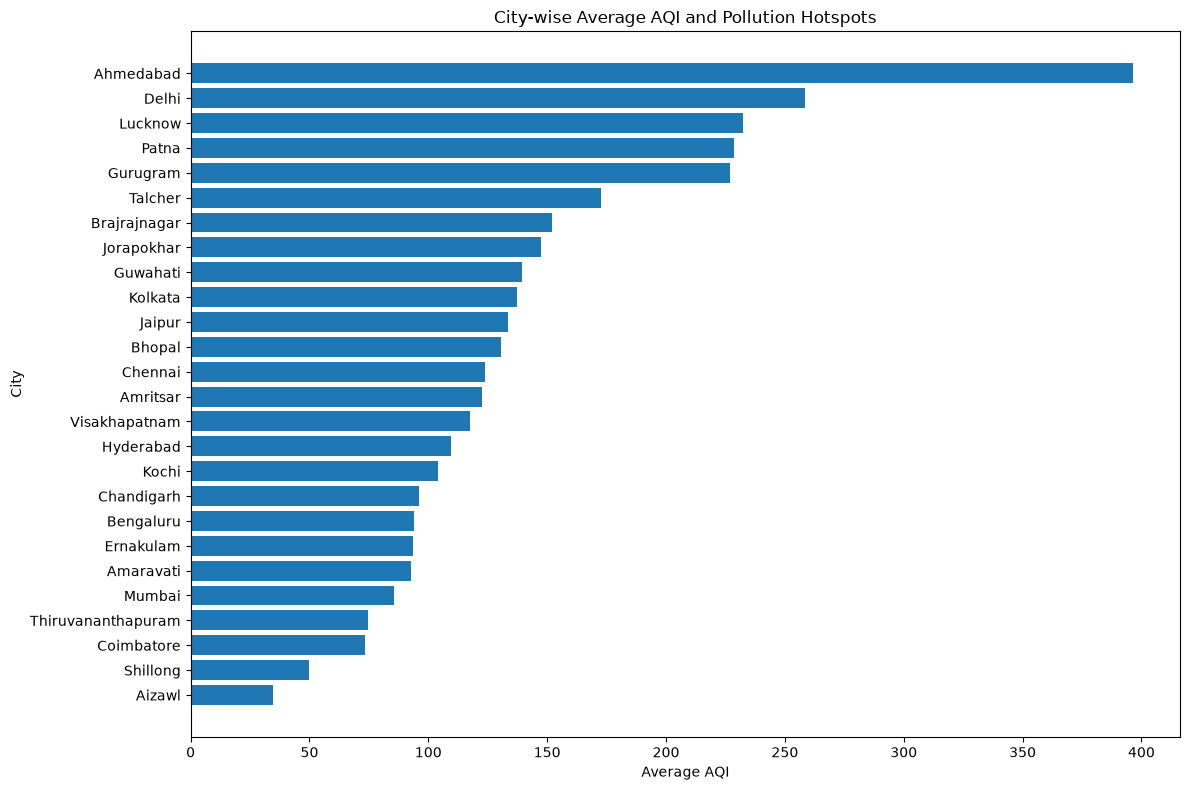

In [7]:
plt.figure(figsize=(12, 8))

plt.barh(city_risk["City"], city_risk["AQI"])

plt.xlabel("Average AQI")
plt.ylabel("City")
plt.title("City-wise Average AQI and Pollution Hotspots")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [8]:
hotspots = city_risk[city_risk["Risk_Level"].isin(["High Risk", "Very High Risk"])]

print("Pollution Hotspots:")
print(hotspots)

Pollution Hotspots:
        City         AQI      Risk_Level
0  Ahmedabad  396.402937  Very High Risk
1      Delhi  258.621453       High Risk
2    Lucknow  232.348183       High Risk
3      Patna  228.524758       High Risk
4   Gurugram  227.107802       High Risk


In [9]:
hotspot_ranking = hotspots.sort_values("AQI", ascending=False).reset_index(drop=True)

hotspot_ranking["Rank"] = hotspot_ranking.index + 1

hotspot_ranking = hotspot_ranking[["Rank", "City", "AQI", "Risk_Level"]]

print("AIR-SHIELD Pollution Hotspot Ranking")
print(hotspot_ranking)

AIR-SHIELD Pollution Hotspot Ranking
   Rank       City         AQI      Risk_Level
0     1  Ahmedabad  396.402937  Very High Risk
1     2      Delhi  258.621453       High Risk
2     3    Lucknow  232.348183       High Risk
3     4      Patna  228.524758       High Risk
4     5   Gurugram  227.107802       High Risk


In [10]:
hotspot_ranking.to_csv(
    "../data/processed/pollution_hotspots.csv",
    index=False
)

print("Hotspot results saved successfully!")

Hotspot results saved successfully!


In [11]:
top_city = city_risk.iloc[0]

print("Most Polluted City:")
print("City:", top_city["City"])
print("Average AQI:", round(top_city["AQI"], 2))
print("Risk Level:", top_city["Risk_Level"])

Most Polluted City:
City: Ahmedabad
Average AQI: 396.4
Risk Level: Very High Risk


In [12]:
risk_counts = city_risk["Risk_Level"].value_counts()

print("Cities by Risk Level:")
print(risk_counts)

Cities by Risk Level:
Risk_Level
Moderate Risk     12
Low Risk           9
High Risk          4
Very High Risk     1
Name: count, dtype: int64


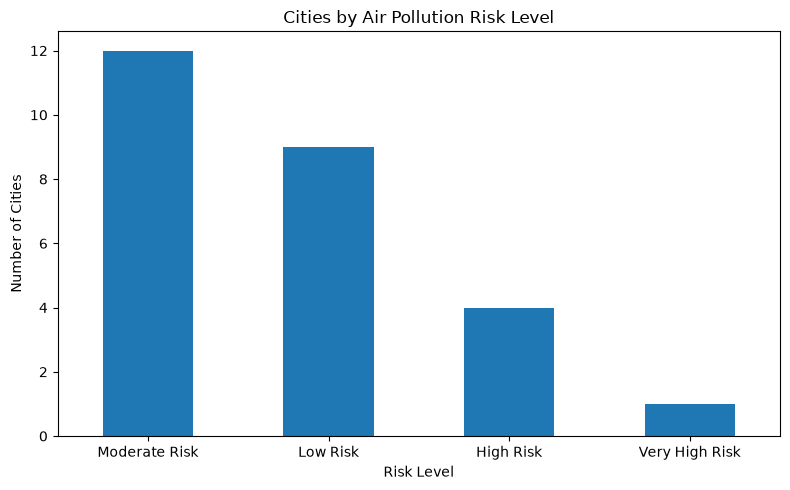

In [13]:
plt.figure(figsize=(8, 5))

risk_counts.plot(kind="bar")

plt.xlabel("Risk Level")
plt.ylabel("Number of Cities")
plt.title("Cities by Air Pollution Risk Level")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [14]:
top_5 = city_risk.nlargest(5, "AQI")[["City", "AQI", "Risk_Level"]]

print("Top 5 Pollution Hotspots")
print(top_5.to_string(index=False))

Top 5 Pollution Hotspots
     City        AQI     Risk_Level
Ahmedabad 396.402937 Very High Risk
    Delhi 258.621453      High Risk
  Lucknow 232.348183      High Risk
    Patna 228.524758      High Risk
 Gurugram 227.107802      High Risk


In [15]:
highest_aqi = city_risk["AQI"].max()
lowest_aqi = city_risk["AQI"].min()
difference = highest_aqi - lowest_aqi

print("Highest Average AQI:", round(highest_aqi, 2))
print("Lowest Average AQI:", round(lowest_aqi, 2))
print("AQI Difference:", round(difference, 2))

Highest Average AQI: 396.4
Lowest Average AQI: 34.78
AQI Difference: 361.62


In [16]:
print("PERSON 2 - HOTSPOT DETECTION CONCLUSION")
print("---------------------------------------")
print("1. Ahmedabad is the most polluted city with an average AQI of 396.40.")
print("2. Delhi, Lucknow, Patna and Gurugram are high-risk pollution hotspots.")
print("3. 1 city is classified as Very High Risk.")
print("4. 4 cities are classified as High Risk.")
print("5. 12 cities are classified as Moderate Risk.")
print("6. 9 cities are classified as Low Risk.")
print("7. The results can be used by AIR-SHIELD to identify cities")
print("   requiring greater pollution monitoring and early warning.")

PERSON 2 - HOTSPOT DETECTION CONCLUSION
---------------------------------------
1. Ahmedabad is the most polluted city with an average AQI of 396.40.
2. Delhi, Lucknow, Patna and Gurugram are high-risk pollution hotspots.
3. 1 city is classified as Very High Risk.
4. 4 cities are classified as High Risk.
5. 12 cities are classified as Moderate Risk.
6. 9 cities are classified as Low Risk.
7. The results can be used by AIR-SHIELD to identify cities
   requiring greater pollution monitoring and early warning.


In [17]:
import os

print(os.path.abspath("../data/processed/pollution_hotspots.csv"))
print(os.path.exists("../data/processed/pollution_hotspots.csv"))

C:\Users\sriha\Downloads\AIR_SHIELD\AIR_SHIELD\data\processed\pollution_hotspots.csv
True


In [18]:
import os
print(os.path.dirname(os.path.abspath("../data/processed/pollution_hotspots.csv")))

C:\Users\sriha\Downloads\AIR_SHIELD\AIR_SHIELD\data\processed


In [19]:
import os
os.startfile(r"C:\Users\sriha\Downloads\AIR_SHIELD\AIR_SHIELD\data\processed")

In [20]:
print(pd.read_csv("../data/processed/pollution_hotspots.csv"))

   Rank       City         AQI      Risk_Level
0     1  Ahmedabad  396.402937  Very High Risk
1     2      Delhi  258.621453       High Risk
2     3    Lucknow  232.348183       High Risk
3     4      Patna  228.524758       High Risk
4     5   Gurugram  227.107802       High Risk


In [21]:
import os

print(os.path.exists("../data/processed/pollution_hotspots.csv"))

True


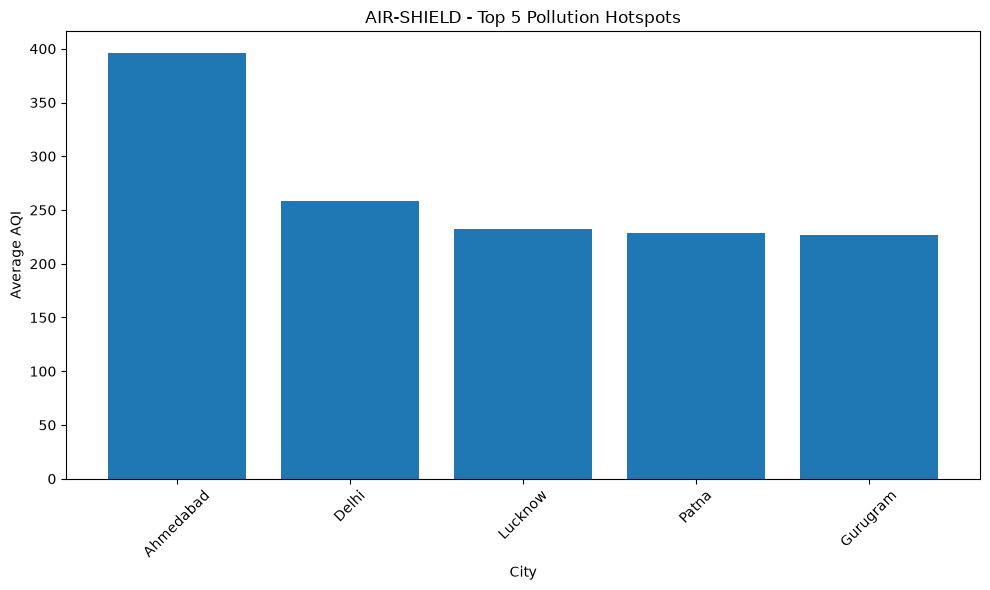

In [22]:
plt.figure(figsize=(10, 6))

plt.bar(
    hotspot_ranking["City"],
    hotspot_ranking["AQI"]
)

plt.xlabel("City")
plt.ylabel("Average AQI")
plt.title("AIR-SHIELD - Top 5 Pollution Hotspots")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [23]:
print("PERSON 2 - HOTSPOT DETECTION")
print("============================")
print("Most Polluted City:", top_city["City"])
print("Average AQI:", round(top_city["AQI"], 2))
print("\nTop 5 Pollution Hotspots:")
print(hotspot_ranking.to_string(index=False))
print("\nRisk Level Summary:")
print(risk_counts)

PERSON 2 - HOTSPOT DETECTION
Most Polluted City: Ahmedabad
Average AQI: 396.4

Top 5 Pollution Hotspots:
 Rank      City        AQI     Risk_Level
    1 Ahmedabad 396.402937 Very High Risk
    2     Delhi 258.621453      High Risk
    3   Lucknow 232.348183      High Risk
    4     Patna 228.524758      High Risk
    5  Gurugram 227.107802      High Risk

Risk Level Summary:
Risk_Level
Moderate Risk     12
Low Risk           9
High Risk          4
Very High Risk     1
Name: count, dtype: int64


In [1]:
import os

print(os.path.abspath("../data/processed/pollution_hotspots.csv"))

C:\Users\sriha\Downloads\AIR_SHIELD\AIR_SHIELD\data\processed\pollution_hotspots.csv
